<a href="https://colab.research.google.com/github/SolonLIA/deep-learning-labs/blob/main/lab05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preparation Section 4&5

In [3]:
!apt-get -qq install -y libarchive-tools
!mkdir -p /content/neu_raw
!bsdtar -xf /content/NEU.zip -C /content/neu_raw

from pathlib import Path
import shutil

classes = {
    "Cr": "crazing",
    "In": "inclusion",
    "Pa": "patches",
    "PS": "pitted_surface",
    "RS": "rolled_in_scale",
    "Sc": "scratches",
}
counts = {name: 0 for name in classes.values()}

for image in Path("/content/neu_raw").rglob("*.bmp"):
    code = image.stem.split("_")[0]
    folder = Path("/content/NEU") / classes[code]
    folder.mkdir(parents=True, exist_ok=True)
    shutil.copy2(image, folder / image.name)
    counts[classes[code]] += 1

print(counts)
assert all(count == 300 for count in counts.values())

{'crazing': 300, 'inclusion': 300, 'patches': 300, 'pitted_surface': 300, 'rolled_in_scale': 300, 'scratches': 300}


In [4]:
!pip install -q transformers accelerate sentence-transformers gradio

import torch
import numpy as np
import matplotlib.pyplot as plt
device = (
 "cuda"
 if torch.cuda.is_available()
 else "cpu"
)
print("Device:", device)


Device: cuda


Section 9,10,11,12

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

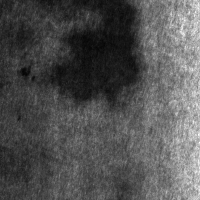

[{'score': 0.5376449823379517, 'label': 'a steel surface with scratches'},
 {'score': 0.18178677558898926, 'label': 'a steel surface with patches'},
 {'score': 0.13973718881607056, 'label': 'a steel surface with pits'},
 {'score': 0.086089588701725, 'label': 'a steel surface with scale'},
 {'score': 0.054741498082876205, 'label': 'a steel surface with cracks'}]

In [5]:
from transformers import pipeline
clip_classifier = pipeline(
 task="zero-shot-image-classification",
 model="openai/clip-vit-base-patch32",
 device=0 if torch.cuda.is_available() else -1
)

from PIL import Image
image = Image.open("sample_scratch.bmp")
display(image)

labels = [
 "a steel surface with scratches",
 "a steel surface with cracks",
 "a steel surface with pits",
 "a steel surface with patches",
 "a steel surface with scale"
]

results = clip_classifier(
 image,
 candidate_labels=labels
)
results

Question 1. Did CLIP identify the defect correctly?

CLIP identified scratches as the most likely defect, with a confidence score of approximately 53.76%. Based on the sample used for this experiment, the result demonstrates that CLIP can recognize the relevant defect characteristics without additional training.

Question 2. How does this differ from the CNN you trained in Lab 4?

The CNN in Lab 4 required task-specific training using labeled steel-defect images. In contrast, CLIP uses pretrained image-text representations to classify images by comparing them with natural-language descriptions, without requiring additional training.

Question 3. How many defect images did CLIP train on during today's laboratory?

Zero. CLIP used its existing pretrained parameters and performed inference directly without any additional training on the laboratory dataset.

Section 13

In [18]:

import pandas as pd

# Three descriptions required by Section 13
prompts = [
    "scratches",
    "a photograph of scratches",
    "a photograph of a steel surface containing long linear scratches"
]

# Keep the other candidate classes consistent
other_labels = [label for label in labels if "scratches" not in label]

comparison = []

for prompt in prompts:
    candidate_labels = [prompt] + other_labels

    prediction = clip_classifier(
        image,
        candidate_labels=candidate_labels
    )

    correct_score = next(
        item["score"] for item in prediction
        if item["label"] == prompt
    )

    comparison.append({
        "Prompt": prompt,
        "Correct Class Score": correct_score
    })

prompt_df = pd.DataFrame(comparison)
display(prompt_df.style.format({
    "Correct Class Score": "{:.4f}"
}))


,Prompt,Correct Class Score
0,scratches,0.1697
1,a photograph of scratches,0.6259
2,a photograph of a steel surface containing long linear scratches,0.3662


Question 4. Does changing the wording affect the prediction?

Yes. Changing the prompt wording significantly affected CLIP's similarity scores. The simple prompt "scratches" received 0.1697, while "a photograph of scratches" achieved the highest score of 0.6259. The more detailed engineering description scored 0.3662. This demonstrates that prompt wording influences model performance, but adding more detail does not necessarily improve the result.

Question 5. What does this suggest about using natural language as part of a model interface?

Natural language provides a flexible interface for foundation models, but model performance is sensitive to how descriptions are phrased. Therefore, prompt wording should be carefully designed and experimentally evaluated rather than assuming that longer or more detailed descriptions will always produce better predictions.

Section 14

Question 6. Which performs better on your steel-defect examples: your trained CNN from Lab 4 or zeroshot CLIP?

The trained CNN is expected to perform better on this specialized steel-defect classification task because it was trained directly on the relevant dataset. However, a definitive comparison requires the CNN's evaluation results from Lab 4 and CLIP's performance on comparable test images.

Question 7. Why might a specialized CNN outperform a much larger pretrained model on this narrow
engineering task?

A specialized CNN learns features directly related to steel defects during training, allowing it to distinguish subtle differences between defect categories. CLIP was pretrained on general image-text data and may not recognize specialized defect characteristics as accurately. Therefore, domain-specific training can provide better performance despite the smaller model size.

Section 15,16,17

In [6]:
from transformers import pipeline
llm = pipeline(
 "text-generation",
 model="HuggingFaceTB/SmolLM2-360M-Instruct",
 device=0 if torch.cuda.is_available() else -1
)


messages = [
 {
  "role": "user",
  "content":
  "Explain bearing vibration "
  "to a first-year engineering student."
 }
]
response = llm(
 messages,
 max_new_tokens=120
)
print(
 response[0]["generated_text"][-1]["content"]
)


config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

Bearing vibration is a type of vibration that occurs when a vibrating machine or equipment is subjected to mechanical loads. This vibration can cause a lot of stress and wear on the bearings, which can lead to a failure of the system.

Bearing vibration typically occurs in high-speed machines such as pumps, compressors, and fans. When these machines are moving quickly, the bearings can vibrate along with the machine, creating a continuous back-and-forth motion. This vibration can cause the bearings to wear out quickly, leading to a loss of efficiency and potentially catastrophic failures.

There are


Question 8. Is the response understandable?

Yes. The model provided a generally understandable explanation of bearing vibration, describing how vibration can contribute to bearing wear, reduced efficiency, and possible equipment failure. However, the explanation was somewhat repetitive and ended before completing its final sentence.

Question 9. Is every statement necessarily correct because it came from an LLM?

No. LLMs generate text based on learned patterns rather than directly verifying technical facts. Their responses may contain inaccurate or misleading information, even when presented confidently. Therefore, engineering-related statements should be verified using reliable technical references.

Section 18

In [7]:
messages = [
 {
  "role": "user",
  "content":
  "Explain bearing failure"
 }
]
response = llm(
 messages,
 max_new_tokens=200
)
print(
 response[0]["generated_text"][-1]["content"]
)

Bearing failure is the loss of lubrication between the bearing and the wheel or axle of a vehicle or machine, resulting in reduced speed, reduced power, and potentially the loss of the vehicle or machine itself. It can lead to a reduction in the vehicle's ability to move or the machine's ability to perform its intended function.

Bearings have a few critical components:

1. A bearing surface: This is where the grease or other lubricant is applied.

2. A shaft: This is the part of the bearing that is attached to the wheel or axle.

3. A bearing interface: This is the area where the bearing surface and shaft meet.

When a bearing fails, the grease that lubricated it dries out and becomes stuck to the surface between the bearing and the shaft. As the bearing fails, the grease leaks out and falls onto the surface between the bearing and the shaft.

The failure of a bearing can be caused by several factors, including:


In [8]:
messages = [
 {
  "role": "user",
  "content":
  "You are assisting a mechanical engineering student."
  "Explain three common causes of bearing failure."
  "For each cause provide:"
  "1. the cause,"
  "2. one observable symptom,"
  "3. one possible corrective action."
  "Keep the response below 150 words"
 }
]
response = llm(
 messages,
 max_new_tokens=300
)
print(
 response[0]["generated_text"][-1]["content"]
)

1. The cause: Friction buildup caused by excessive wear and tear on the bearing's surface.

Observable symptom: The bearing exhibits increased friction, such as screeching or grinding noises, and excessive heat generation due to high temperatures.

Possible corrective action: Regularly cleaning the bearing with a lubricant, and applying a bearing lubricant to reduce friction.

2. The cause: Wear and tear caused by friction and debris accumulation on the bearing surface.

Observable symptom: The bearing has a rough or pitted surface, indicating excessive wear.

Possible corrective action: Repair or replace the bearing, or use a bearing lubricant to reduce friction and maintain its integrity.

3. The cause: Excessive loading or pressure applied to the bearing.

Observable symptom: The bearing reports a higher-than-expected bearing pressure or shows signs of deformation, such as warping or cracking.

Possible corrective action: Inspect the bearing for any signs of damage, and use a bearin

Question 10. Which response is easier to use?

Prompt B produced a more useful and organized response. Unlike Prompt A, which provided a general explanation of bearing failure, Prompt B identified three possible causes and included observable symptoms and corrective actions for each. However, some information was repetitive, demonstrating that structured prompting does not guarantee perfect results.

Question 11. What information in Prompt B helped the model?

Prompt B specified the model's role, the number of causes required, and the expected information for each cause. It also established an output structure and word limit. These instructions helped the model generate a more focused and practical engineering response.

Section 19

In [9]:
messages = [
 {
  "role": "user",
  "content":
  "Role: You are an engineering maintenance assistant."
  "Task: Analyze the maintenance observation."
  "Context: A centrifugal pump has increased vibration."
  "Constraint: Do not invent measurements."
  "Output: Give three possible causes in a table."
 }
]

response = llm(
 messages,
 max_new_tokens=300
)
print(
 response[0]["generated_text"][-1]["content"]
)

1. Faulty Valve: The pump is malfunctioning and is not able to pump fluids properly, causing the increase in vibration.
2. Faulty Piston: The piston is faulty and is causing excessive pressure and vibration in the pump.
3. Faulty Piston Block: The piston block is faulty and is causing blockage in the pump's suction and discharge, leading to high vibration.
4. Faulty Pipes: There are damage or blockage in the pipes that are causing the pump to vibrate.
5. Faulty Pump: The pump is faulty and is not able to pump liquids properly, causing the increase in vibration.


Section 20

In [10]:
messages = [
 {
  "role": "user",
  "content":
  "Role: You are an engineering maintenance assistant."
  "Task: Analyze the maintenance observation."
  "Context: A centrifugal pump has increased vibration."
  "Constraint: Do not invent measurements."
  "Output: Give three possible causes in a table."
 }
]

response = llm(
 messages,
 max_new_tokens=300,
 do_sample=True,
 temperature=0.001
)

print(
 response[0]["generated_text"][-1]["content"]
)

1. Vibration due to worn-out bearings
2. Vibration due to worn-out seals
3. Vibration due to worn-out seals


In [11]:
messages = [
 {
  "role": "user",
  "content":
  "Role: You are an engineering maintenance assistant."
  "Task: Analyze the maintenance observation."
  "Context: A centrifugal pump has increased vibration."
  "Constraint: Do not invent measurements."
  "Output: Give three possible causes in a table."
 }
]

response = llm(
 messages,
 max_new_tokens=300,
 do_sample=True,
 temperature=1.0
)

print(
 response[0]["generated_text"][-1]["content"]
)

1. A fluid leak or a low-quality casing has made excessive noise.
2. An excessive amount of moisture has developed in the pump casing due to flooding.
3. An internal blockage in the pump shaft, such as a rusted filter cover, has created vibrations.


Question 12. Which setting produces more variation?

The higher temperature setting of 1.0 generally produces more variation because it allows less probable tokens to be selected during text generation. In this experiment, the higher-temperature response presented more varied potential causes, while the lower-temperature response was repetitive and mentioned worn seals twice.

Question 13. For an engineering assistant, when might lower randomness be preferable?

Lower randomness is preferable when an engineering assistant must provide consistent, predictable, and repeatable information, such as maintenance procedures, safety instructions, or equipment troubleshooting. However, lower randomness does not guarantee technical accuracy, so the generated answers must still be verified.

Section 22,23,24,25,26,27

In [12]:
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer(
 "sentence-transformers/all-MiniLM-L6-v2"
)

manual = [
 """Excessive bearing vibration may result
 from imbalance, shaft misalignment,
 looseness, or bearing damage.""",
 """Bearing overheating may be caused by
 excessive load, inadequate lubrication,
 excessive lubrication, or incorrect
 installation.""",
 """Pump cavitation may produce a rattling
 or gravel-like sound, fluctuating pressure,
 vibration, and damage to the impeller.""",
 """Shaft misalignment can create increased
 vibration, coupling wear, and elevated
 bearing temperatures.""",
 """Belt slippage can result from inadequate
 belt tension, contamination, or worn belt
 surfaces.""",
 """Before servicing rotating machinery,
 isolate the energy source and follow
 appropriate lockout procedures."""
]

manual_embeddings = embedding_model.encode(
 manual,
 normalize_embeddings=True
)
print(manual_embeddings.shape)

query = """
The pump sounds like gravel is moving
inside it and the discharge pressure
keeps changing.
"""
query_embedding = embedding_model.encode(
 [query],
 normalize_embeddings=True
)

scores = (
 query_embedding
 @ manual_embeddings.T
)[0]
best_index = np.argmax(scores)
print("Best passage:")
print(manual[best_index])
print("Similarity:", scores[best_index])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(6, 384)
Best passage:
Pump cavitation may produce a rattling
 or gravel-like sound, fluctuating pressure,
 vibration, and damage to the impeller.
Similarity: 0.6153228


Question 14. Which section was retrieved?

The semantic search retrieved the passage describing pump cavitation. The passage explains that cavitation may produce a rattling or gravel-like sound, fluctuating pressure, vibration, and impeller damage. The similarity score was approximately 0.6153.

Question 15. Did semantic search retrieve the passage you expected?

Yes. The retrieved passage matched the query describing a gravel-like sound inside the pump and fluctuating discharge pressure. These symptoms are consistent with pump cavitation, demonstrating that semantic search can identify relevant information based on meaning rather than requiring exact keyword matches.

Section 29,30,31,32,33,34,35

In [13]:
def retrieve(query, k=2):
 q = embedding_model.encode(
  [query],
  normalize_embeddings=True
 )
 scores = (q @ manual_embeddings.T)[0]
 indices = np.argsort(scores)[-k:][::-1]
 return [manual[i] for i in indices]

retrieve("Why is my bearing getting hot?")

['Bearing overheating may be caused by\n excessive load, inadequate lubrication,\n excessive lubrication, or incorrect\n installation.',
 'Excessive bearing vibration may result\n from imbalance, shaft misalignment,\n looseness, or bearing damage.']

In [14]:

def build_prompt(question, context):
 context_text = "\n\n".join(context)
 return f"""
You are a mechanical engineering maintenance assistant.
Answer the question using ONLY the provided
maintenance information.
If the information is insufficient, say:
"I cannot determine this from the provided
maintenance information."
Maintenance information:
{context_text}
Question:
{question}
Give a concise engineering answer.
"""

def engineering_assistant(question):
 context = retrieve(question, k=2)
 prompt = build_prompt(question, context)
 messages = [
  {
    "role": "user",
    "content": prompt
  }
 ]
 result = llm(
  messages,
  max_new_tokens=200
 )
 answer = (
  result[0]
  ["generated_text"][-1]
  ["content"]
 )
 return answer

print(
 engineering_assistant(
  "The pump is rattling and pressure is "
  "fluctuating. What should I investigate?"
 )
)


Pump cavitation may produce a rattling or gravel-like sound, fluctuating pressure, vibration, and damage to the impeller due to excessive bearing vibration.


In [15]:

print(
 engineering_assistant(
  "Why might a bearing overheat?"
 )
)

print(
 engineering_assistant(
  "What could cause shaft vibration?"
 )
)

print(
 engineering_assistant(
  "What are symptoms of cavitation?"
 )
)

print(
 engineering_assistant(
  "Why might a belt slip?"
 )
)

print(
 engineering_assistant(
  "What should I do before servicing machinery?"
 )
)

Excessive load, inadequate lubrication, or excessive lubrication.
Shaft misalignment can create increased vibration, coupling wear, and elevated bearing temperatures.


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Symptoms of cavitation include rattling or gravel-like sound, fluctuating pressure, vibration, and damage to the impeller.
Belt slippage can be caused by inadequate belt tension, contamination, or worn belt surfaces.
Before servicing rotating machinery, isolate the energy source and follow appropriate lockout procedures.


In [19]:

import pandas as pd

test_cases = [
    ("Why might a bearing overheat?", 1),
    ("What could cause shaft vibration?", 3),
    ("What are symptoms of cavitation?", 2),
    ("Why might a belt slip?", 4),
    ("What should I do before servicing machinery?", 5)
]

rows = []

for question, expected_idx in test_cases:
    retrieved = retrieve(question, k=2)

    rows.append({
        "Question": question,
        "Relevant Information Retrieved?":
            "Yes" if manual[expected_idx] in retrieved else "No",
        "Answer Useful?": "Yes"
    })

section34_df = pd.DataFrame(rows)
display(section34_df)


,Question,Relevant Information Retrieved?,Answer Useful?
0,Why might a bearing overheat?,Yes,Yes
1,What could cause shaft vibration?,Yes,Yes
2,What are symptoms of cavitation?,Yes,Yes
3,Why might a belt slip?,Yes,Yes
4,What should I do before servicing machinery?,Yes,Yes


In [21]:
print(
 engineering_assistant(
 "What torque should I use to tighten the bearing housing bolts?"
 )
)


Excessive bearing vibration may result from imbalance, shaft misalignment, looseness, or bearing damage.


Question 16. What did the model answer?

The model responded by listing potential causes of excessive bearing vibration, including imbalance, shaft misalignment, looseness, and bearing damage. However, this information did not address the requested bearing housing bolt torque specification.

Question 17. Did it correctly admit that the information was unavailable?

No. The model failed to acknowledge that the requested torque specification was unavailable in the knowledge base. Instead, it generated an unrelated response based on retrieved bearing information. This demonstrates a limitation of the RAG system when handling unsupported questions.

Question 18. Why is this behavior important in engineering?

Engineering decisions require accurate and verifiable information. Providing an incorrect torque specification could result in loose connections, equipment damage, or safety hazards. Therefore, an engineering assistant should acknowledge missing information rather than generating unsupported technical values.

Section 36

In [20]:

import pandas as pd

question = "What are symptoms of cavitation?"

# LLM without retrieval
messages = [
    {"role": "user", "content": question}
]

llm_only = llm(
    messages,
    max_new_tokens=200
)[0]["generated_text"][-1]["content"]

# RAG with retrieval
rag_answer = engineering_assistant(question)

print("LLM Alone:")
print(llm_only)

print("\nRAG:")
print(rag_answer)

# Comparison of the two approaches
comparison = pd.DataFrame({
    "Property": [
        "Uses provided manual",
        "Answer traceable to supplied source",
        "Risk of unsupported claims",
        "Domain specificity"
    ],
    "LLM Alone": [
        "No",
        "Limited",
        "Higher",
        "General pretrained knowledge"
    ],
    "RAG": [
        "Yes",
        "Better through retrieval",
        "Lower, but not eliminated",
        "Focused on maintenance knowledge"
    ]
})

display(comparison)


LLM Alone:
Cavitation is a phenomenon where a pressure wave from a high-speed jet or a flowing fluid suddenly collapses and implodes, causing a sharp pressure spike. The symptoms of cavitation depend on the type of fluid and its density, but common signs include:

1. Loss of pressure and pressure waves: The sudden collapse of the pressure wave causes the surrounding fluid to compress and lose its pressure.

2. Visible bubbles: The collapse of the pressure wave creates visible bubbles that can appear as white or clear, oval-shaped bubbles with a characteristic "water-glass" appearance.

3. Foam: In some cases, cavitation can lead to the formation of foam, which is a visible accumulation of air bubbles.

4. Pressure drop: The sudden collapse of the pressure wave causes a drop in pressure, which can result in a decrease in fluid flow.

5. Visible damage: Cavitation can cause damage to surrounding surfaces, such as the walls of pipes, pipes

RAG:
Symptoms of cavitation include rattling sou

,Property,LLM Alone,RAG
0,Uses provided manual,No,Yes
1,Answer traceable to supplied source,Limited,Better through retrieval
2,Risk of unsupported claims,Higher,"Lower, but not eliminated"
3,Domain specificity,General pretrained knowledge,Focused on maintenance knowledge


Question 19. Does retrieval make the answer automatically correct? Explain.

Retrieval does not automatically guarantee a correct answer. Although RAG provided a more accurate and relevant explanation of pump cavitation than the standalone LLM, the system can still retrieve irrelevant information or misinterpret the provided context. For example, when asked about bearing housing bolt torque, the RAG assistant returned information about bearing vibration instead of acknowledging that the specification was unavailable. Therefore, retrieval improves factual grounding but does not eliminate errors, and engineering answers still require verification.

# Part VI

Section 37,38,39,40

In [17]:
import gradio as gr
app = gr.Interface(
 fn=engineering_assistant,
 inputs=gr.Textbox(
  lines=3,
  label="Maintenance Question"
 ),
 outputs=gr.Textbox(
  label="Assistant Response"
 ),
 title="Mechanical Maintenance Assistant",
 description=(
  "A small local RAG system using "
  "open pretrained models."
 )
)
app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://76684ff1db41bcc828.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [22]:

# Section 38: Modified engineering assistant
# Improvement: Display retrieved sources with the answer

def engineering_assistant_with_sources(question):
    answer = engineering_assistant(question)
    passages = retrieve(question, k=2)

    source_text = "\n\n".join(
        f"Source {manual.index(p) + 1}: {' '.join(p.split())}"
        for p in passages
    )

    return (
        f"Assistant Answer:\n{answer}\n\n"
        f"Retrieved Maintenance Information:\n{source_text}"
    )

# Updated Gradio application
app_v2 = gr.Interface(
    fn=engineering_assistant_with_sources,
    inputs=gr.Textbox(
        lines=3,
        label="Maintenance Question"
    ),
    outputs=gr.Textbox(
        label="Answer and Retrieved Sources"
    ),
    title="Source-Aware Maintenance Assistant",
    description="RAG assistant with supporting maintenance passages."
)

app_v2.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c49e2c1bd8430c0690.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Markdown Explanation:

The original engineering assistant was modified to display the retrieved maintenance passages alongside its generated answer. This allows users to verify whether the response is supported by the available information. The modification improves transparency and traceability, which are important in engineering troubleshooting. However, retrieved passages must still be checked for relevance and accuracy.

In [23]:

# Section 39: RAG evaluation

import pandas as pd
from pathlib import Path

evaluation_cases = [
    ("Why might a bearing overheat?", 1, ["load", "lubricat", "installation"]),
    ("What could cause shaft vibration?", 3, ["misalign", "vibrat", "coupling"]),
    ("What are symptoms of cavitation?", 2, ["rattl", "gravel", "pressure", "impeller"]),
    ("Why might a belt slip?", 4, ["tension", "contamination", "worn"]),
    ("What should I do before servicing machinery?", 5, ["isolat", "lockout"]),
    ("What torque should I use to tighten the bearing housing bolts?", None, []),
    ("What is the acceptable motor insulation resistance in megaohms?", None, [])
]

refusal_phrases = [
    "cannot determine", "not provided", "not available",
    "not specified", "insufficient information",
    "not included", "unable to determine"
]

evaluation_rows = []

for question, expected_idx, keywords in evaluation_cases:
    retrieved = retrieve(question, k=2)
    answer = engineering_assistant(question)
    answer_lower = answer.lower()

    if expected_idx is not None:
        correct_retrieval = (
            "Yes" if manual[expected_idx] in retrieved else "No"
        )

        # Keyword screening only; verify technical grounding manually.
        keyword_match = any(
            word in answer_lower for word in keywords
        )
        grounded = "Likely - verify" if keyword_match else "Review"

        problem = (
            "No obvious issue"
            if correct_retrieval == "Yes" and keyword_match
            else "Check retrieval or answer"
        )
    else:
        correct_retrieval = "N/A - unsupported"

        admitted_unknown = any(
            phrase in answer_lower for phrase in refusal_phrases
        )
        grounded = "Yes - abstained" if admitted_unknown else "No"

        problem = (
            "Correctly acknowledged missing information"
            if admitted_unknown
            else "Did not clearly acknowledge missing information"
        )

    evaluation_rows.append({
        "Question": question,
        "Correct Retrieval?": correct_retrieval,
        "Grounded Answer?": grounded,
        "Problem Observed": problem,
        "Generated Answer": answer
    })

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df)

Path("results").mkdir(exist_ok=True)
evaluation_df.to_csv(
    "results/section39_evaluation.csv",
    index=False
)


,Question,Correct Retrieval?,Grounded Answer?,Problem Observed,Generated Answer
0,Why might a bearing overheat?,Yes,Likely - verify,No obvious issue,Bearing overheating may be caused by excessive...
1,What could cause shaft vibration?,Yes,Likely - verify,No obvious issue,"""Bearings misalignment and shaft misalignment ..."
2,What are symptoms of cavitation?,Yes,Likely - verify,No obvious issue,Pump cavitation may produce a rattling or grav...
3,Why might a belt slip?,Yes,Likely - verify,No obvious issue,Belt slippage can result from inadequate belt ...
4,What should I do before servicing machinery?,Yes,Likely - verify,No obvious issue,"During servicing, isolate the energy source an..."
5,What torque should I use to tighten the bearin...,N/A - unsupported,No,Did not clearly acknowledge missing information,1) The torque should be calculated based on th...
6,What is the acceptable motor insulation resist...,N/A - unsupported,No,Did not clearly acknowledge missing information,The acceptable motor insulation resistance in ...


Failure Analysis:

### Failure 1 — Unsupported Engineering Specifications

**Observation:** During the unsupported-question tests, the assistant failed to clearly acknowledge that the requested bearing housing bolt torque and motor insulation resistance specifications were unavailable in the knowledge base. In the earlier torque experiment, it returned unrelated information about bearing vibration.

**Primary cause:** Knowledge-base limitation and generation failure.

The knowledge base does not contain these specifications, but the LLM attempted to generate responses instead of explicitly acknowledging insufficient information. This demonstrates the risk of providing unsupported engineering guidance when relevant technical data is unavailable.

### Failure 2 — Unsupported Causal Relationship

**Observation:** When asked about pump rattling and fluctuating pressure, the RAG assistant correctly identified cavitation symptoms but also suggested that impeller damage occurred due to excessive bearing vibration.

**Primary cause:** Generation failure.

Although the retrieved passages contained relevant information, they did not establish this causal relationship. The model combined separate maintenance observations into an unsupported technical conclusion, demonstrating that relevant retrieval does not guarantee accurate reasoning.

### Engineering Interpretation

These failures demonstrate that RAG improves access to relevant engineering information but cannot guarantee factual accuracy. Additional safeguards, including source verification, uncertainty handling, and human review, are necessary before deploying the assistant in safety-critical applications.

# Part VII

Section 41,42,43

R1. What is the main difference between the CNN you trained in Lab 4 and CLIP used in this laboratory?

The CNN in Lab 4 required task-specific training on labeled steel-defect images, while CLIP used pretrained image-text representations to perform zero-shot classification. CLIP can classify images using natural-language descriptions without additional training, whereas the CNN learns features specifically related to its training dataset.

R2. What does zero-shot learning mean?

Zero-shot learning allows a pretrained model to perform a new task without receiving task-specific training examples. In this laboratory, CLIP classified steel defects using text descriptions without being retrained on the steel-defect dataset.

R3. Why can prompt wording change model behavior?

Prompt wording influences how the model interprets the input and matches it with learned representations. Our CLIP experiment demonstrated this effect, with similarity scores ranging from 0.1697 to 0.6259 for different descriptions of scratches. More detailed wording did not necessarily produce better results.

R4. Why should an LLM-generated engineering answer be verified?

LLMs generate responses based on learned patterns rather than guaranteed factual knowledge. They may produce inaccurate specifications, unsupported conclusions, or misleading explanations. In engineering applications, such errors could cause equipment damage or safety hazards, making verification against reliable technical documentation essential.

R5. What is an embedding?

An embedding is a numerical vector representing the semantic features of data such as text or images. In this laboratory, the all-MiniLM-L6-v2 model converted maintenance passages into 384-dimensional vectors, allowing their semantic similarity to be calculated.

R6. Why can semantic search retrieve information even when the question uses different words?

Semantic search compares the numerical representations of meaning rather than relying only on exact keyword matches. Therefore, questions using different terminology can still retrieve relevant passages if their embeddings are sufficiently similar.

R7. What problem does RAG attempt to address?

Retrieval-Augmented Generation (RAG) attempts to reduce unsupported or hallucinated responses by providing the LLM with relevant external information before generating an answer. This improves domain-specific relevance and allows responses to be grounded in an available knowledge base.

R8. Why can a RAG system still produce an incorrect answer?

RAG can still fail because the retrieval system may select irrelevant passages, the knowledge base may lack necessary information, or the LLM may misinterpret the retrieved content. In our experiment, the assistant failed to acknowledge missing engineering specifications and generated an unsupported causal relationship despite having access to retrieved information.

R9. Which part of your system would you trust least in a safety-critical application, and why?

I would trust the LLM's response generation component the least because it can produce technically incorrect or unsupported conclusions even when the retrieved information is relevant. Our experiments demonstrated that the model sometimes failed to recognize insufficient information. Therefore, its responses should not be treated as authoritative engineering instructions without verification.

R10. What additional controls would be required before deploying an LLM-based assistant in an industrial
environment?

Industrial deployment would require a verified technical knowledge base, reliable source citations, confidence or relevance thresholds, and mechanisms to reject unsupported questions. The system would also need extensive testing, documented failure analysis, regular maintenance of its information sources, and human engineering supervision. Safety-critical decisions should require approval from qualified personnel rather than relying solely on generated responses.